# Exact parameter-response memory

This executed report compares two supported quantum learning tasks before and after caching their exact parameter-dependent responses. It reads saved evidence and launches **no benchmark or QPU jobs**.

The primary comparison includes complete fresh-process overhead. Qiskit receives both the previous spatial-symmetry optimization and, in a stronger control, exactly the same response reuse as GroupMemory. An analytic classical control evaluates the identical model.

In [1]:
from pathlib import Path
import csv, hashlib, io, json, os, statistics, zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

root = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "pyproject.toml").exists())
results = Path(os.environ.get("GROUPMEMORY_RESULTS", root / "results" / "parameter-response"))
analysis = json.loads((results / "analysis.json").read_text())
config = json.loads((results / "config.json").read_text())
summary = {(r["condition"], r["method"]): r for r in analysis["summary"]}
comparisons = {(r["condition"], r["baseline"]): r for r in analysis["comparisons"]}
conditions = [c["id"] for c in analysis["conditions"]]
labels = {
    "group_memory_response": "GroupMemory response",
    "qiskit_response": "Qiskit + same response",
    "group_memory_previous": "Previous GroupMemory",
    "qiskit_symmetry": "Previous symmetry Qiskit",
    "classical_same_model": "Analytic identical model",
    "classical": "Classical task model",
}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})


## Evidence audit

Every same-model method must match the prior Qiskit predictions and complete training trajectory at absolute tolerance $10^{-10}$. The Qiskit response control must perform the same native work. The archive, frozen sources and final checkpoint are checked independently below. No tolerance is adjusted to obtain a performance result.

In [2]:
verified_files = 0
for line in (results / "SHA256SUMS.txt").read_text().splitlines():
    digest, name = line.split("  ", 1)
    assert hashlib.sha256((results / name).read_bytes()).hexdigest() == digest, name
    verified_files += 1
with zipfile.ZipFile(results / "source_snapshot.zip") as source:
    for name, digest in config["source_hashes"].items():
        assert hashlib.sha256(source.read("group_memory_qml/" + name)).hexdigest() == digest
with zipfile.ZipFile(results / "raw_attempts.zip") as archive:
    rows = [json.loads(archive.read(f"attempts/{i:05d}.json")) for i in range(len(config["plan"]))]
blocks = {}
for spec, row in zip(config["plan"], rows, strict=True):
    assert row["spec"] == spec
    assert row["source_hashes"] == config["source_hashes"]
    assert row["status"] == "SUCCESS"
    key = (spec["condition"], spec["seed"], spec["repeat"])
    blocks.setdefault(key, {})[spec["method"]] = row
worst = 0.
for key, block in blocks.items():
    reference = block["qiskit_symmetry"]
    data = lambda r: r["diagnostics"].get("dataset_sha256", r["diagnostics"].get("data_sha256"))
    assert all(data(row) == data(reference) for row in block.values())
    for method, row in block.items():
        if method != "classical":
            err = np.max(np.abs(np.asarray(row["validation_vector"]) - reference["validation_vector"]))
            assert err <= 1e-10, (key, method, err)
            worst = max(worst, float(err))
    for field in ("evaluations", "total_cx"):
        assert block["group_memory_response"][field] == block["qiskit_response"][field]
manifest = json.loads((results / "checkpoints" / "manifest.json").read_text())
checkpoint_file = results / "checkpoints" / manifest["latest"]
assert hashlib.sha256(checkpoint_file.read_bytes()).hexdigest() == manifest["latest_sha256"]
checkpoint = json.loads(checkpoint_file.read_text())
assert checkpoint["config_sha256"] == hashlib.sha256((results / "config.json").read_bytes()).hexdigest()
assert checkpoint["completed_attempts"] == len(rows)
assert checkpoint["deadline_unix"] == manifest["deadline_unix"] == json.loads((results / "authorization.json").read_text())["deadline_unix"]
with zipfile.ZipFile(results / "raw_attempts.zip") as archive:
    assert hashlib.sha256(archive.read(f"attempts/{len(rows)-1:05d}.json")).hexdigest() == checkpoint["last_result_sha256"]
display(Markdown(f"**Verified {len(rows)} attempts, {len(blocks)} matched blocks, {verified_files} artifact hashes and frozen source/checkpoint identities.** Maximum trajectory error: `{worst:.3g}`."))


**Verified 540 attempts, 90 matched blocks, 32 artifact hashes and frozen source/checkpoint identities.** Maximum trajectory error: `3.62e-14`.

## Full training time and accuracy

Each table entry is a median of per-seed medians, including launch, imports, preparation, fresh compilation, all probe/check circuits, learning, prediction, JSON writing and shutdown. Scores average five seeds. All methods use the same generated splits, and all same-model methods use the same learning updates. Related sensor views are not independent examples.

In [3]:
lines = ["| Workload | Group response | Previous symmetry Qiskit | Qiskit + response | Analytic same model | Classical task | Accuracy: same model / task |", "|---|---:|---:|---:|---:|---:|---:|"]
for cid in conditions:
    methods = ("group_memory_response", "qiskit_symmetry", "qiskit_response", "classical_same_model", "classical")
    times = [f"{summary[cid, m]['process_wall_s']:.3f} s" for m in methods]
    quality = f"{summary[cid, methods[0]]['accuracy']:.1%} / {summary[cid, 'classical']['accuracy']:.1%}"
    lines.append(f"| {cid} | " + " | ".join(times) + f" | {quality} |")
display(Markdown("\n".join(lines)))


| Workload | Group response | Previous symmetry Qiskit | Qiskit + response | Analytic same model | Classical task | Accuracy: same model / task |
|---|---:|---:|---:|---:|---:|---:|
| sensor-1 | 1.696 s | 1.990 s | 1.743 s | 1.256 s | 1.271 s | 86.2% / 100.0% |
| sensor-5 | 1.853 s | 3.560 s | 1.854 s | 1.290 s | 1.348 s | 95.0% / 100.0% |
| sensor-20 | 2.156 s | 9.519 s | 2.080 s | 1.590 s | 1.428 s | 98.8% / 100.0% |
| spin-1 | 0.394 s | 0.397 s | 0.401 s | 0.110 s | 1.284 s | 100.0% / 100.0% |
| spin-3 | 0.386 s | 0.456 s | 0.385 s | 0.108 s | 1.371 s | 100.0% / 100.0% |
| spin-8 | 0.395 s | 0.682 s | 0.389 s | 0.112 s | 1.303 s | 100.0% / 100.0% |

## Where does calibration pay off?

A descriptive win requires five complete seeds, at least three matching repeats each, every seed median faster and at least 5% median paired saving. This is a descriptive rule, not a significance test. Both panels use the same scale; ranges are observed seeds, not confidence intervals.

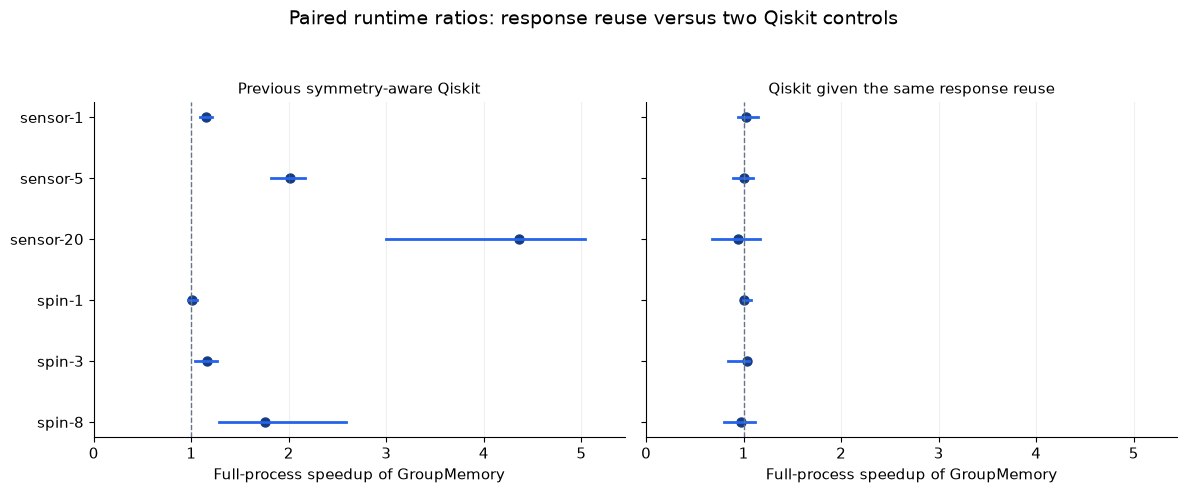

| Workload | Versus previous Qiskit | Meets rule | Versus response Qiskit | Meets rule |
|---|---:|---|---:|---|
| sensor-1 | 1.15× | True | 1.03× | False |
| sensor-5 | 2.01× | True | 1.01× | False |
| sensor-20 | 4.36× | True | 0.94× | False |
| spin-1 | 1.01× | False | 1.01× | False |
| spin-3 | 1.16× | True | 1.03× | False |
| spin-8 | 1.75× | True | 0.98× | False |

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
baselines = ("qiskit_symmetry", "qiskit_response")
maximum = max(comparisons[c, b]["maximum_seed_speedup"] for c in conditions for b in baselines)
for ax, baseline, title in zip(axes, baselines, ("Previous symmetry-aware Qiskit", "Qiskit given the same response reuse")):
    for i, cid in enumerate(conditions):
        row = comparisons[cid, baseline]
        ax.plot([row["minimum_seed_speedup"], row["maximum_seed_speedup"]], [i, i], lw=2, color="#2563eb")
        ax.scatter(row["paired_speedup"], i, s=42, color="#163c80")
    ax.axvline(1, ls="--", color="#64748b", lw=1)
    ax.set_xlim(0, max(1.2, maximum) * 1.08)
    ax.set_yticks(range(len(conditions)), conditions)
    ax.set_xlabel("Full-process speedup of GroupMemory")
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", alpha=.2)
axes[0].invert_yaxis()
fig.suptitle("Paired runtime ratios: response reuse versus two Qiskit controls", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, .94))
fig.savefig(results / "notebook_paired_speedups.png", dpi=150)
plt.show()
lines = ["| Workload | Versus previous Qiskit | Meets rule | Versus response Qiskit | Meets rule |", "|---|---:|---|---:|---|"]
for cid in conditions:
    a, b = [comparisons[cid, m] for m in baselines]
    lines.append(f"| {cid} | {a['paired_speedup']:.2f}× | {a['descriptive_win']} | {b['paired_speedup']:.2f}× | {b['descriptive_win']} |")
display(Markdown("\n".join(lines)))


## Absolute runtime and actual circuit work

The analytic control calculates the identical quantum-circuit model without quantum-library probes. A fast response cache does not establish quantum advantage over that control. The task-specific classical model is a different learner, so its quality must accompany runtime.

CNOT totals count actual probe/direct forward circuit work. The old sensor engine also performs classical reverse-gradient propagations; their time is included, but they are not mislabeled as QPU CNOT executions.

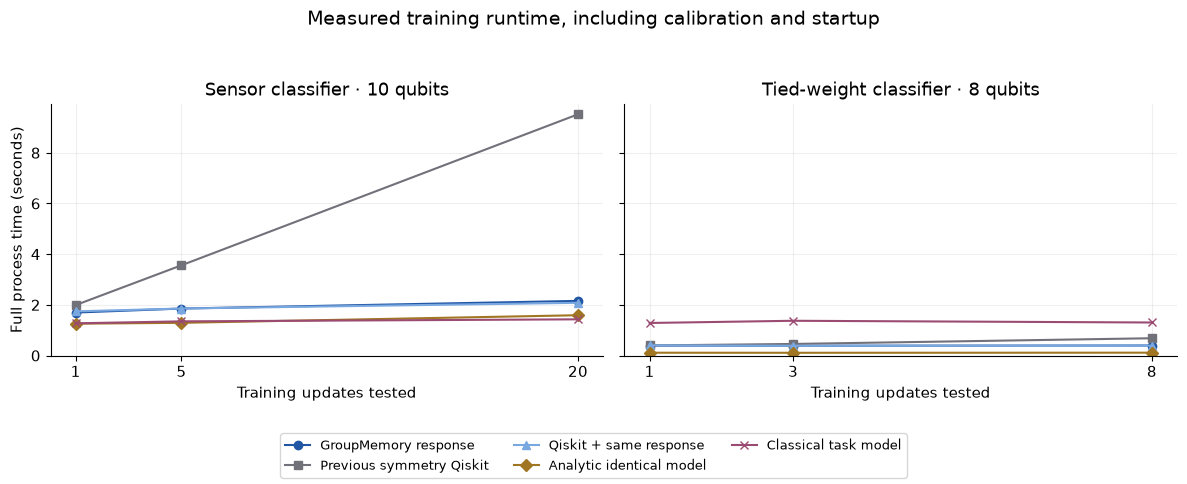

| Workload | Response native evaluations | Previous Qiskit evaluations | Forward CNOT saving |
|---|---:|---:|---:|
| sensor-1 | 96 | 48 | -100.0% |
| sensor-5 | 96 | 112 | 14.3% |
| sensor-20 | 96 | 352 | 72.7% |
| spin-1 | 48 | 60 | 20.0% |
| spin-3 | 48 | 132 | 63.6% |
| spin-8 | 48 | 312 | 84.6% |

In [5]:
methods = ("group_memory_response", "qiskit_symmetry", "qiskit_response", "classical_same_model", "classical")
colors = ["#2156a5", "#71717a", "#79a7df", "#a17622", "#9b4b72"]
markers = ["o", "s", "^", "D", "x"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, family, title in zip(axes, ("sensor", "spin"), ("Sensor classifier · 10 qubits", "Tied-weight classifier · 8 qubits")):
    selected = [c for c in conditions if c.startswith(family)]
    ticks = [int(c.split("-")[-1]) for c in selected]
    for method, color, marker in zip(methods, colors, markers):
        ax.plot(ticks, [summary[c, method]["process_wall_s"] for c in selected], color=color, marker=marker, label=labels[method])
    ax.set_xticks(ticks)
    ax.set_xlabel("Training updates tested")
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=.2)
axes[0].set_ylabel("Full process time (seconds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Measured training runtime, including calibration and startup", fontsize=14)
fig.tight_layout(rect=(0, .13, 1, .94))
fig.savefig(results / "notebook_absolute_runtime.png", dpi=150)
plt.show()
lines = ["| Workload | Response native evaluations | Previous Qiskit evaluations | Forward CNOT saving |", "|---|---:|---:|---:|"]
for cid in conditions:
    a, b = summary[cid, "group_memory_response"], summary[cid, "qiskit_symmetry"]
    saving = 1 - a["total_cx"] / b["total_cx"]
    lines.append(f"| {cid} | {a['evaluations']:.0f} | {b['evaluations']:.0f} | {saving:.1%} |")
display(Markdown("\n".join(lines)))


## Costs, scope and reproducibility

Response coefficients are learned from four sensor probe settings or two spin probe settings, plus one independently checked setting in each case. Every probe is included in the clocks and native-work counts. Coefficients persist across parameter updates; unknown test-only inputs use one direct execution. Unsupported architectures use documented fallbacks.

These are small synthetic, ideal CPU experiments with known architecture-specific trigonometric bases. Both models have efficient classical closed forms. Finite-shot estimation, noisy-hardware equivalence and practical quantum training advantage are not established. Fourier response reconstruction has prior literature; see `docs/parameter_response.md`.

The source archive, seed/config journal, environment and dependency versions are packaged with this report. Reproduction commands are in that document. The report can be executed without rerunning any simulations.

In [6]:
ledger = json.loads((results / "wall_accounting.json").read_text())
display(Markdown(f"Main benchmark: **{ledger['main_external_wall_s']/60:.2f} minutes**, including the parent process. Worker process clocks sum to **{analysis['sum_process_wall_s']/60:.2f} minutes**. Independent tests, checkpoint/resume pilot, readout and packaging are separate costs; package installation is excluded."))
print(json.dumps(ledger, indent=2))


Main benchmark: **15.73 minutes**, including the parent process. Worker process clocks sum to **15.70 minutes**. Independent tests, checkpoint/resume pilot, readout and packaging are separate costs; package installation is excluded.

{
  "main_external_wall_s": 943.857140875014,
  "main_worker_wall_sum_s": 942.1246452853084,
  "main_parent_overhead_s": 1.7324955897056498,
  "main_loop_wall_s": 943.6180067919777,
  "preflight_external_s": 14.005273083981592,
  "additional_protocol_tests_external_s": 1.068035208,
  "pilot_elapsed_including_resume_pause_s": 95.7171151638031,
  "pilot_worker_wall_sum_s": 75.86834908364108,
  "main_report_s": 0.7837737079826184,
  "pilot_report_s": 0.4211260420270264,
  "scope": "Main external clock includes parent and every fresh worker launch through exit. Each method pays its own imports, data, setup, native compilation, all probes/checks, cache planning, training, predictions, serialization and shutdown. Tests and separate pilot are not pooled. Installation, human/agent authoring and exploratory development checks excluded. Notebook/export and packaging receipts are separate.",
  "quick_command_loop_wall_s": 14.734213124960661,
  "quick_report_s": 0.44780758302658796,
  "initial_pac